# 🧠 NeuroMap v2 — Model Architecture & NeuroSeg Preprocessing

This notebook covers:
1. Environment setup
2. Dataset exploration
3. **NeuroSeg** — proposed hybrid segmentation algorithm (5 stages, no pretrained weights)
4. Segmented dataset visualization
5. EfficientNet-B3 model with Grad-CAM hooks
6. Test forward pass verification

> Run before `02_Training_Evaluation.ipynb`


## 1. Setup & Imports

In [14]:
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu118 -q
!pip install opencv-python Pillow scikit-learn matplotlib seaborn -q
print("✅ Packages ready")



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
✅ Packages ready


In [15]:
import os, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms, datasets
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from PIL import Image
import matplotlib.pyplot as plt
import cv2

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Device : {DEVICE}")

# 2. Print the specific GPU details based on the active backend
if DEVICE.type == "cuda":
    print(f"GPU    : {torch.cuda.get_device_name(0)}")
elif DEVICE.type == "mps":
    # MPS does not use get_device_name(), but it runs on your Mac's Apple Silicon GPU
    print("GPU    : Apple Silicon Integrated GPU (MPS)")


Device : mps
GPU    : Apple Silicon Integrated GPU (MPS)


In [16]:
DATA_DIR       = "./Datasets"
TRAIN_DIR      = os.path.join(DATA_DIR, "Training")
TEST_DIR       = os.path.join(DATA_DIR, "Testing")
CHECKPOINT_DIR = "./checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

IMG_SIZE    = 224
NUM_CLASSES = 4
CLASS_NAMES = ['glioma', 'meningioma', 'notumor', 'pituitary']
CLASS_COLORS = ['#E24B4A', '#EF9F27', '#4CAF76', '#378ADD']
print("Config ready ✅")


Config ready ✅


## 2. Dataset Exploration

Training: {'glioma': 2063, 'meningioma': 2105, 'notumor': 1400, 'pituitary': 2330} → Total: 7898
Testing:  {'glioma': 400, 'meningioma': 400, 'notumor': 400, 'pituitary': 400} → Total: 1600


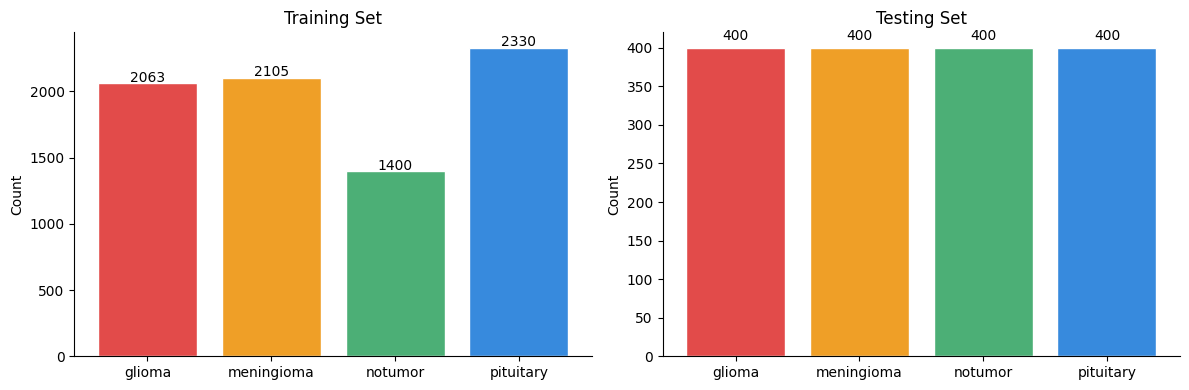

In [17]:
def count_images(root):
    return {c: len(os.listdir(os.path.join(root, c)))
            for c in sorted(os.listdir(root))
            if os.path.isdir(os.path.join(root, c))}

train_counts = count_images(TRAIN_DIR)
test_counts  = count_images(TEST_DIR)
print("Training:", train_counts, "→ Total:", sum(train_counts.values()))
print("Testing: ", test_counts,  "→ Total:", sum(test_counts.values()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (counts, title) in zip(axes, [(train_counts,"Training"),(test_counts,"Testing")]):
    bars = ax.bar(list(counts.keys()), list(counts.values()), color=CLASS_COLORS, edgecolor='white')
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+10,
                str(int(b.get_height())), ha='center', fontsize=10)
    ax.set_title(f"{title} Set"); ax.set_ylabel("Count")
    ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'class_distribution.png'), dpi=150)
plt.show()


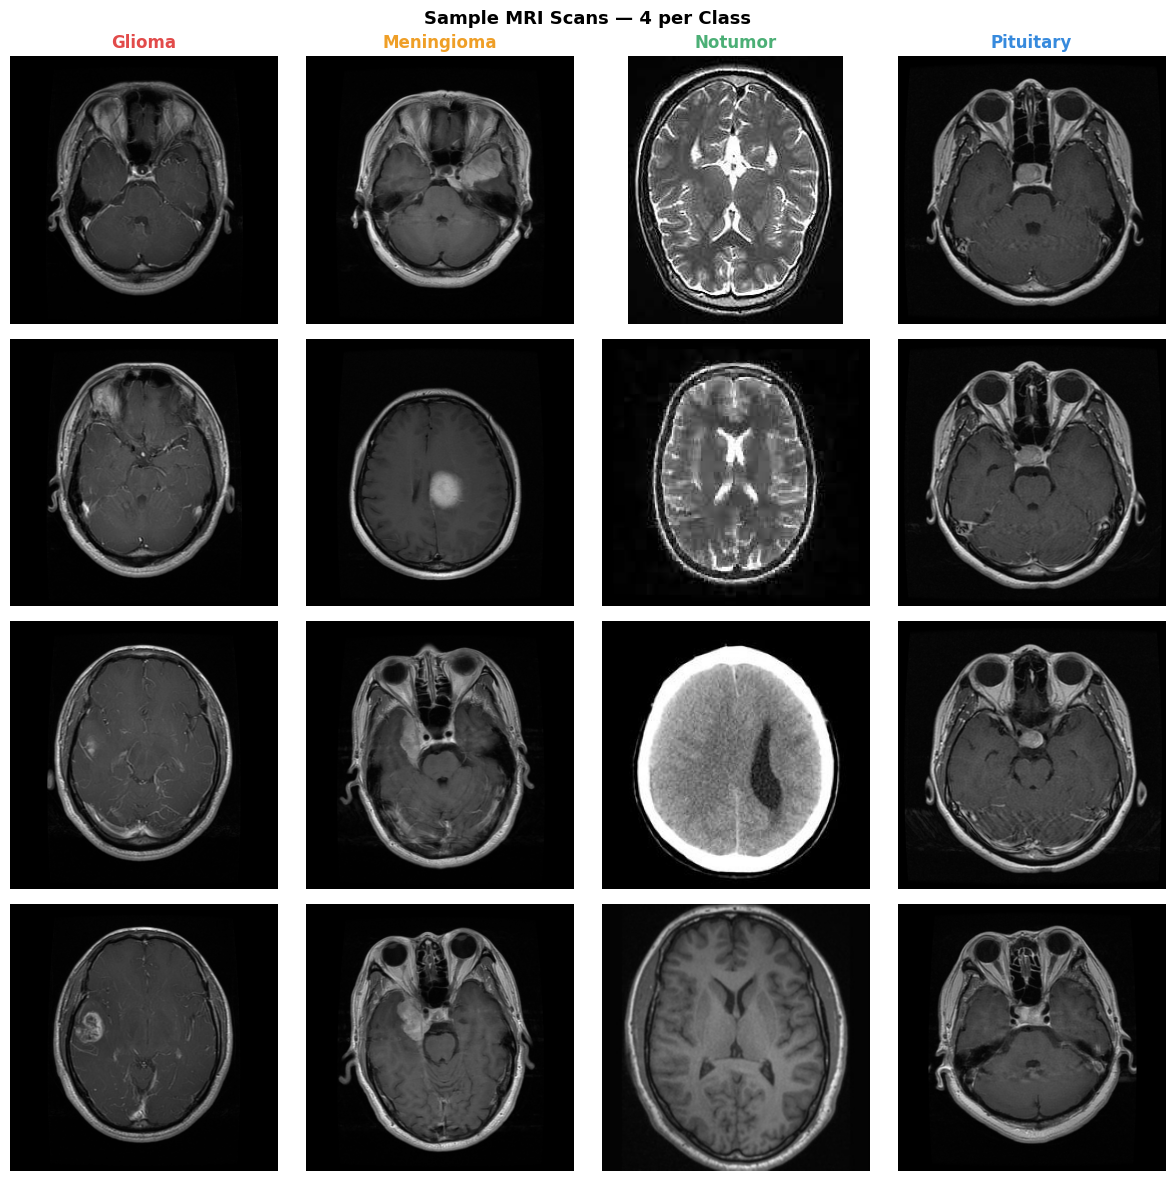

In [18]:
# Sample images from each class
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
fig.suptitle("Sample MRI Scans — 4 per Class", fontsize=13, fontweight='bold')
for col, cls in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TRAIN_DIR, cls)
    for row, fname in enumerate(sorted(os.listdir(cls_dir))[:4]):
        img = Image.open(os.path.join(cls_dir, fname)).convert('RGB')
        axes[row][col].imshow(img); axes[row][col].axis('off')
        if row == 0:
            axes[row][col].set_title(cls.capitalize(), color=CLASS_COLORS[col], fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'sample_images.png'), dpi=150)
plt.show()


## 3. NeuroSeg — Proposed Hybrid Segmentation Algorithm

A custom 5-stage pipeline. **No pretrained weights, no external models.**

| Stage | Technique | Purpose |
|---|---|---|
| 1 | CLAHE | Normalize contrast across different scanners |
| 2 | Dual Threshold (Otsu ∩ Adaptive) | Handle uneven illumination |
| 3 | Morphological Reconstruction | Remove noise, fill holes |
| 4 | Watershed | Precise brain boundary |
| 5 | Convex Hull | Smooth anatomically consistent mask |


In [19]:
class NeuroSeg:
    """
    NeuroSeg: Proposed Hybrid Brain Segmentation Algorithm.
    5-stage classical CV pipeline — no pretrained weights.
    """

    def __init__(self, clahe_clip=3.0, clahe_grid=(8,8),
                 morph_kernel_sz=15, target_size=224, debug=False):
        self.clahe_clip      = clahe_clip
        self.clahe_grid      = clahe_grid
        self.morph_kernel_sz = morph_kernel_sz
        self.target_size     = target_size
        self.debug           = debug
        self.stages          = {}

    def _stage1_clahe(self, gray):
        """Stage 1: CLAHE — adaptive contrast normalization."""
        clahe = cv2.createCLAHE(clipLimit=self.clahe_clip,
                                 tileGridSize=self.clahe_grid)
        out = clahe.apply(gray)
        if self.debug: self.stages['1_clahe'] = out.copy()
        return out

    def _stage2_dual_threshold(self, enhanced):
        """
        Stage 2: Dual Threshold Fusion.
        Otsu (global) AND Adaptive Gaussian (local) → bitwise AND.
        Pixels must pass BOTH thresholds to be foreground.
        Handles uneven illumination that single-threshold fails on.
        """
        blurred  = cv2.GaussianBlur(enhanced, (5,5), 0)
        _, otsu  = cv2.threshold(blurred, 0, 255,
                                  cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        adaptive = cv2.adaptiveThreshold(blurred, 255,
                       cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                       cv2.THRESH_BINARY, blockSize=35, C=2)
        fused = cv2.bitwise_and(otsu, adaptive)
        if self.debug:
            self.stages['2a_otsu']    = otsu.copy()
            self.stages['2b_adaptive']= adaptive.copy()
            self.stages['2c_fused']   = fused.copy()
        return fused

    def _stage3_morphological(self, binary):
        """
        Stage 3: Morphological Reconstruction.
        Open  → removes small isolated noise blobs.
        Close → fills internal holes in the brain mask.
        Dilate → recovers boundary pixels lost during opening.
        Elliptical kernel gives smoother, anatomically natural shapes.
        """
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,
                                       (self.morph_kernel_sz, self.morph_kernel_sz))
        opened  = cv2.morphologyEx(binary, cv2.MORPH_OPEN,  k)
        closed  = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, k)
        dilated = cv2.dilate(closed, k, iterations=1)
        if self.debug: self.stages['3_morphological'] = dilated.copy()
        return dilated

    def _stage4_watershed(self, enhanced, morphed):
        """
        Stage 4: Watershed Boundary Refinement.
        Uses distance transform to find sure-foreground seeds (>50% of peak dist).
        Watershed grows from seeds, stops at intensity ridges = skull-brain boundary.
        Gives sub-pixel-precise segmentation vs blocky morphological boundaries.
        """
        dist    = cv2.distanceTransform(morphed, cv2.DIST_L2, 5)
        _, sfg  = cv2.threshold(dist, 0.5 * dist.max(), 255, 0)
        sfg     = sfg.astype(np.uint8)
        sbg     = cv2.dilate(morphed,
                              cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21,21)),
                              iterations=3)
        unknown = cv2.subtract(sbg, sfg)
        _, markers = cv2.connectedComponents(sfg)
        markers = markers + 1
        markers[unknown == 255] = 0
        cv2.watershed(cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR), markers)
        refined = np.zeros_like(morphed)
        refined[markers > 1] = 255
        if self.debug: self.stages['4_watershed'] = refined.copy()
        return refined

    def _stage5_convex_hull(self, refined):
        """
        Stage 5: Convex Hull Smoothing.
        Keep largest connected component (the brain).
        Wrap in convex hull → smooth, anatomically consistent boundary.
        Brains are approximately convex so this is medically valid.
        """
        n, labels, stats, _ = cv2.connectedComponentsWithStats(refined)
        final = np.zeros_like(refined)
        if n > 1:
            lg  = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
            tmp = np.zeros_like(refined)
            tmp[labels == lg] = 255
            cnts, _ = cv2.findContours(tmp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if cnts:
                hull = cv2.convexHull(max(cnts, key=cv2.contourArea))
                cv2.fillConvexPoly(final, hull, 255)
        else:
            final = refined
        if self.debug: self.stages['5_convex_hull'] = final.copy()
        return final

    def segment(self, img_pil):
        img_np = np.array(img_pil.convert('RGB'))
        h, w   = img_np.shape[:2]
        if w > h * 1.5:
            img_np = img_np[:, :w//2]   # crop side-by-side composite scans

        gray     = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        if self.debug: self.stages['0_grayscale'] = gray.copy()

        enhanced = self._stage1_clahe(gray)
        binary   = self._stage2_dual_threshold(enhanced)
        morphed  = self._stage3_morphological(binary)
        refined  = self._stage4_watershed(enhanced, morphed)
        final    = self._stage5_convex_hull(refined)

        masked = cv2.bitwise_and(img_np, img_np, mask=final)
        coords = cv2.findNonZero(final)
        if coords is not None:
            x, y, bw, bh = cv2.boundingRect(coords)
            pad  = int(min(bw, bh) * 0.05)
            x    = max(0, x - pad); y = max(0, y - pad)
            bw   = min(img_np.shape[1]-x, bw+2*pad)
            bh   = min(img_np.shape[0]-y, bh+2*pad)
            masked = masked[y:y+bh, x:x+bw]
            bbox   = (x, y, bw, bh)
        else:
            bbox = (0, 0, img_np.shape[1], img_np.shape[0])

        resized = cv2.resize(masked, (self.target_size, self.target_size),
                              interpolation=cv2.INTER_LINEAR)
        return Image.fromarray(resized), final, bbox

    def visualize_pipeline(self, img_pil, save_path=None):
        """Show all 5 intermediate stages for debugging / presentation."""
        self.debug = True
        seg_pil, _, _ = self.segment(img_pil)
        self.debug = False

        stage_order = ['0_grayscale','1_clahe','2c_fused',
                       '3_morphological','4_watershed','5_convex_hull']
        stage_titles = ['0 Grayscale','1 CLAHE','2 Dual Threshold',
                        '3 Morphological','4 Watershed','5 Convex Hull']

        fig, axes = plt.subplots(1, 8, figsize=(20, 3))
        fig.suptitle("NeuroSeg Pipeline — All Stages", fontsize=12, fontweight='bold')

        axes[0].imshow(img_pil.resize((224,224))); axes[0].set_title("Input", fontsize=9, fontweight='bold')
        for i, (key, title) in enumerate(zip(stage_order, stage_titles)):
            img = self.stages.get(key)
            if img is not None:
                axes[i+1].imshow(img, cmap='gray')
            axes[i+1].set_title(title, fontsize=8)
        axes[7].imshow(seg_pil); axes[7].set_title("Output", fontsize=9, fontweight='bold', color='green')
        for ax in axes: ax.axis('off')

        plt.tight_layout()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches='tight')
            print(f"Saved → {save_path}")
        plt.show()
        return seg_pil


# ── Instantiate ───────────────────────────────────────────────────────────────
neuroseg = NeuroSeg(clahe_clip=3.0, clahe_grid=(8,8),
                     morph_kernel_sz=15, target_size=224)
print("NeuroSeg initialized ✅")
print("  Stage 1: CLAHE adaptive contrast normalization")
print("  Stage 2: Dual threshold (Otsu ∩ Adaptive Gaussian)")
print("  Stage 3: Morphological reconstruction (open→close→dilate)")
print("  Stage 4: Watershed boundary refinement")
print("  Stage 5: Convex hull smoothing + largest component")


NeuroSeg initialized ✅
  Stage 1: CLAHE adaptive contrast normalization
  Stage 2: Dual threshold (Otsu ∩ Adaptive Gaussian)
  Stage 3: Morphological reconstruction (open→close→dilate)
  Stage 4: Watershed boundary refinement
  Stage 5: Convex hull smoothing + largest component


Saved → ./checkpoints/neuroseg_pipeline_stages.png


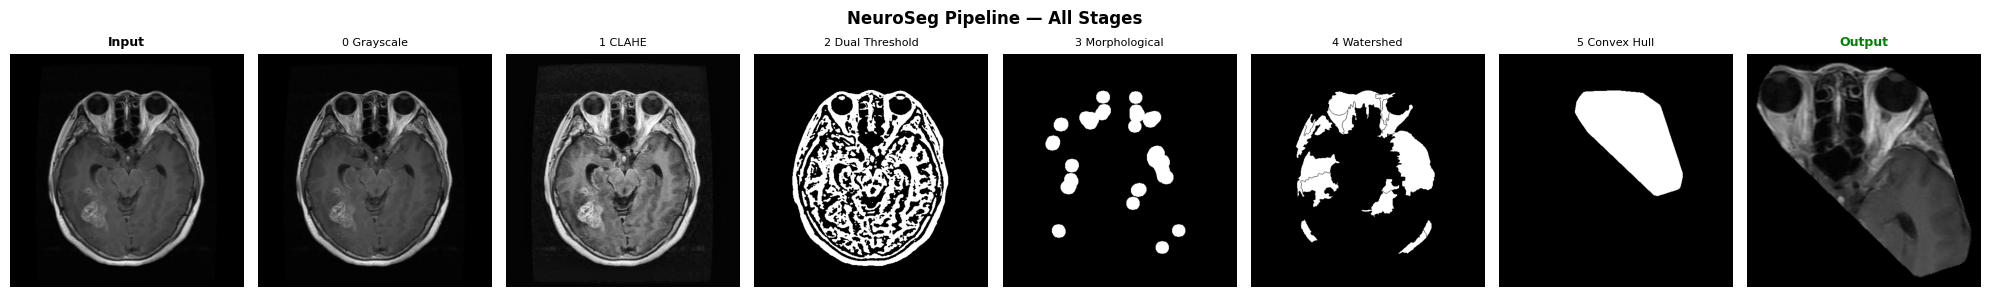

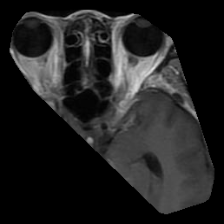

In [20]:
# ── Visualize full pipeline on one image ─────────────────────────────────────
sample_path = os.path.join(TRAIN_DIR, CLASS_NAMES[0],
                            os.listdir(os.path.join(TRAIN_DIR, CLASS_NAMES[0]))[0])
sample_pil  = Image.open(sample_path).convert('RGB')

neuroseg.visualize_pipeline(
    sample_pil,
    save_path=os.path.join(CHECKPOINT_DIR, 'neuroseg_pipeline_stages.png')
)


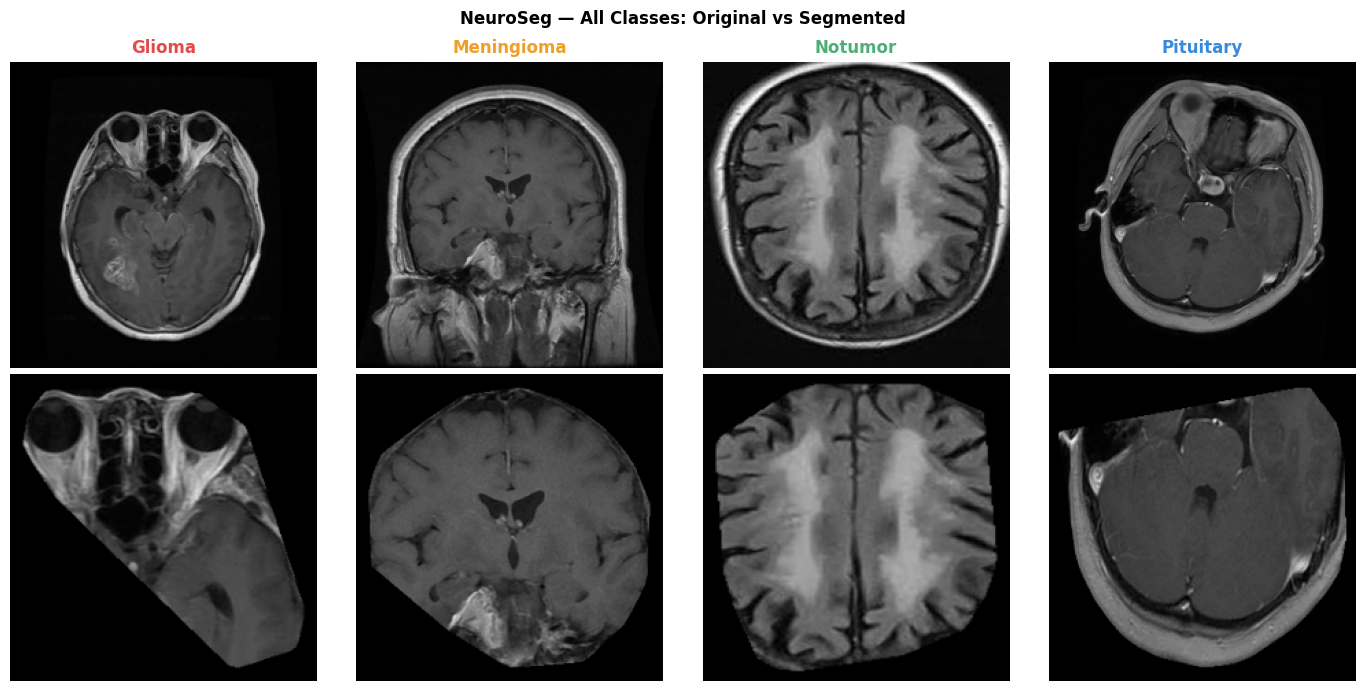

In [21]:
# ── Test NeuroSeg on all 4 classes ───────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.suptitle("NeuroSeg — All Classes: Original vs Segmented", fontsize=12, fontweight='bold')

for col, cls in enumerate(CLASS_NAMES):
    cls_dir  = os.path.join(TRAIN_DIR, cls)
    img_pil  = Image.open(os.path.join(cls_dir, os.listdir(cls_dir)[0])).convert('RGB')
    seg_pil, mask, bbox = neuroseg.segment(img_pil)

    axes[0][col].imshow(img_pil.resize((224,224)))
    axes[0][col].set_title(cls.capitalize(), color=CLASS_COLORS[col], fontweight='bold')
    axes[0][col].axis('off')
    if col == 0: axes[0][col].set_ylabel("Original", fontsize=9)

    axes[1][col].imshow(seg_pil)
    axes[1][col].axis('off')
    if col == 0: axes[1][col].set_ylabel("NeuroSeg", fontsize=9, color='green')

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'neuroseg_all_classes.png'), dpi=150)
plt.show()


## 4. Transforms & SegmentedMRIDataset

In [22]:
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.85, 1.15)),
    transforms.RandomGrayscale(p=0.1),
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Transforms defined ✅")
for t in train_transforms.transforms:
    print(f"  → {t.__class__.__name__}")


Transforms defined ✅
  → Resize
  → RandomCrop
  → RandomHorizontalFlip
  → RandomVerticalFlip
  → RandomRotation
  → ColorJitter
  → RandomAffine
  → RandomGrayscale
  → GaussianBlur
  → ToTensor
  → Normalize


In [23]:
class SegmentedMRIDataset(Dataset):
    """
    Custom Dataset applying NeuroSeg before transforms.
    Drop-in replacement for datasets.ImageFolder.
    Training and inference use the SAME segmentation pipeline
    so model never sees unprocessed images.
    """

    def __init__(self, root_dir, transform=None, target_size=224):
        self.transform  = transform
        self.segmenter  = NeuroSeg(target_size=target_size)
        self.samples    = []
        self.class_to_idx = {}

        classes = sorted([c for c in os.listdir(root_dir)
                           if os.path.isdir(os.path.join(root_dir, c))])
        self.class_to_idx = {cls: i for i, cls in enumerate(classes)}

        for cls in classes:
            cls_dir = os.path.join(root_dir, cls)
            for fname in os.listdir(cls_dir):
                if fname.lower().endswith(('.jpg','.jpeg','.png','.webp','.bmp')):
                    self.samples.append((os.path.join(cls_dir, fname),
                                         self.class_to_idx[cls]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img_pil     = Image.open(path).convert('RGB')
        try:
            seg_pil, _, _ = self.segmenter.segment(img_pil)
        except Exception:
            seg_pil = img_pil.resize((224, 224))
        if self.transform:
            seg_pil = self.transform(seg_pil)
        return seg_pil, label


# Quick test
ds = SegmentedMRIDataset(TRAIN_DIR, transform=val_transforms)
t, l = ds[0]
print(f"SegmentedMRIDataset ✅  |  size: {len(ds)}  |  tensor: {t.shape}  |  label: {CLASS_NAMES[l]}")


SegmentedMRIDataset ✅  |  size: 7898  |  tensor: torch.Size([3, 224, 224])  |  label: glioma


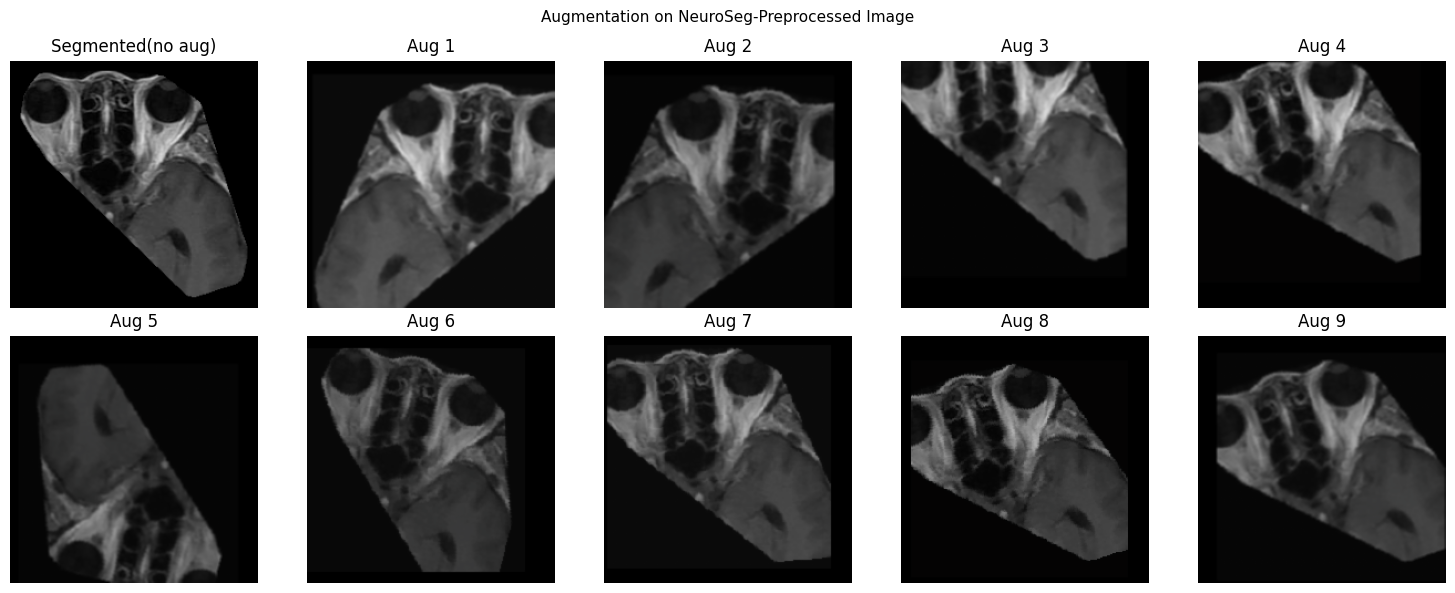

In [24]:
# ── Visualize augmentation on a segmented image ──────────────────────────────
seg_pil, _, _ = neuroseg.segment(Image.open(
    os.path.join(TRAIN_DIR, CLASS_NAMES[0],
                  os.listdir(os.path.join(TRAIN_DIR, CLASS_NAMES[0]))[0])
).convert('RGB'))

def denorm(tensor):
    m = torch.tensor([0.485,0.456,0.406]).view(3,1,1)
    s = torch.tensor([0.229,0.224,0.225]).view(3,1,1)
    return (tensor*s+m).clamp(0,1).permute(1,2,0).numpy()

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Augmentation on NeuroSeg-Preprocessed Image", fontsize=11)
axes[0][0].imshow(seg_pil); axes[0][0].set_title("Segmented(no aug)")
axes[0][0].axis('off')
for i in range(1, 10):
    ax = axes[i//5][i%5]
    ax.imshow(denorm(train_transforms(seg_pil)))
    ax.set_title(f"Aug {i}"); ax.axis('off')
plt.tight_layout()
plt.show()


## 5. EfficientNet-B3 + Grad-CAM Model

In [25]:
class NeuroMapModel(nn.Module):
    """EfficientNet-B3 fine-tuned for 4-class brain MRI classification."""

    def __init__(self, num_classes=4, dropout_rate=0.4):
        super().__init__()
        self.backbone = models.efficientnet_b3(
            weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1
        )
        total = len(list(self.backbone.features.children()))
        for i, layer in enumerate(self.backbone.features.children()):
            if i < int(total * 0.8):
                for p in layer.parameters():
                    p.requires_grad = False

        in_f = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(p=dropout_rate, inplace=True),
            nn.Linear(in_f, 512), nn.ReLU(),
            nn.Dropout(p=dropout_rate/2),
            nn.Linear(512, num_classes)
        )
        self.gradients = None; self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def fwd(m,i,o): self.activations = o.detach()
        def bwd(m,gi,go): self.gradients = go[0].detach()
        self.backbone.features[-1].register_forward_hook(fwd)
        self.backbone.features[-1].register_full_backward_hook(bwd)

    def forward(self, x): return self.backbone(x)

    def get_gradcam(self, x, class_idx=None):
        self.eval()
        x = x.clone().requires_grad_(True)
        logits = self.forward(x)
        probs  = F.softmax(logits, dim=1)
        pred   = logits.argmax(1).item()
        target = class_idx if class_idx is not None else pred
        self.backbone.zero_grad()
        oh = torch.zeros_like(logits); oh[0][target] = 1
        logits.backward(gradient=oh, retain_graph=True)
        w   = self.gradients.mean(dim=(2,3), keepdim=True)
        cam = (w * self.activations).sum(dim=1).squeeze().cpu().numpy()
        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (224,224))
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, pred, probs.squeeze().detach().cpu().numpy()


model = NeuroMapModel(NUM_CLASSES).to(DEVICE)
total      = sum(p.numel() for p in model.parameters())
trainable  = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params     : {total:,}")
print(f"Trainable params : {trainable:,}  ({100*trainable/total:.1f}%)")
print(f"Frozen params    : {total-trainable:,}")


Total params     : 11,485,228
Trainable params : 4,666,110  (40.6%)
Frozen params    : 6,819,118


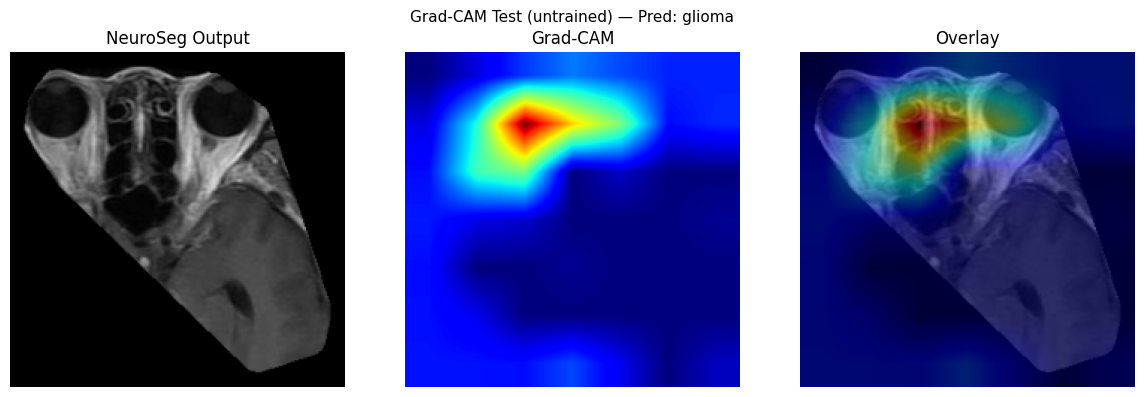

Pipeline test complete ✅  →  Next: 02_Training_Evaluation.ipynb


In [26]:
# ── Test Grad-CAM on a segmented image ───────────────────────────────────────
sample_pil  = Image.open(os.path.join(TRAIN_DIR, CLASS_NAMES[0],
              os.listdir(os.path.join(TRAIN_DIR, CLASS_NAMES[0]))[0])).convert('RGB')
seg_pil, _, _ = neuroseg.segment(sample_pil)
seg_np      = np.array(seg_pil)
tensor      = val_transforms(seg_pil).unsqueeze(0).to(DEVICE)

heatmap, pred_idx, probs = model.get_gradcam(tensor)
hm_uint8    = (heatmap * 255).astype(np.uint8)
hm_color    = cv2.cvtColor(cv2.applyColorMap(hm_uint8, cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
overlay     = (seg_np.astype(float)*0.55 + hm_color.astype(float)*0.45).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(f"Grad-CAM Test (untrained) — Pred: {CLASS_NAMES[pred_idx]}", fontsize=11)
axes[0].imshow(seg_pil);                axes[0].set_title("NeuroSeg Output"); axes[0].axis('off')
axes[1].imshow(heatmap, cmap='jet');    axes[1].set_title("Grad-CAM");        axes[1].axis('off')
axes[2].imshow(overlay);               axes[2].set_title("Overlay");          axes[2].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'gradcam_untrained_test.png'), dpi=150)
plt.show()
print("Pipeline test complete ✅  →  Next: 02_Training_Evaluation.ipynb")
